In [2]:
pip install statsmodels matplotlib

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf
import pandas as pd
import warnings
from statsmodels.tsa.stattools import adfuller, kpss
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [15]:

import pandas as pd

# 1. Load the dataset and parse the 'date' column
df = pd.read_csv(r"/content/drive/MyDrive/afg-rainfall-subnat-full.csv", parse_dates=["date"])

# 2. Filter for Admin Level 1 (Provinces) to avoid double-counting with Admin Level 2 (Districts)
a1 = df[df.adm_level == 1].copy()

# 3. Weight rainfall and long-term average by pixel count (area)
a1["w_rfh"] = a1.rfh * a1.n_pixels
a1["w_avg"] = a1.rfh_avg * a1.n_pixels

# 4. Group by date and compute the national weighted mean
g = a1.groupby("date")[["w_rfh", "w_avg", "n_pixels"]].sum()
nat = pd.DataFrame({
    "rfh": g.w_rfh / g.n_pixels,      # national mean rainfall per dekad (mm)
    "rfh_avg": g.w_avg / g.n_pixels,  # long-term average (climatology baseline)
})

# 5. Inspect the resulting time series
print("Shape:", nat.shape)
print("\nHead:\n", nat.head())
print("\nTail:\n", nat.tail())
print("\nDay intervals between observations:\n", nat.index.to_series().diff().dt.days.value_counts())


Shape: (1651, 2)

Head:
                   rfh    rfh_avg
date                            
1981-01-01  15.242465  10.874725
1981-01-11  14.790754  11.526814
1981-01-21  29.077247  13.295164
1981-02-01  12.023414  19.321074
1981-02-11  20.281209  18.747544

Tail:
                  rfh   rfh_avg
date                          
2026-09-21  1.086532  0.843792
2026-10-01  1.537322  1.916964
2026-10-11  1.983670  2.142994
2026-10-21  1.594917  2.826173
2026-11-01  5.205643  5.543053

Day intervals between observations:
 date
10.0    1283
11.0     321
8.0       35
9.0       11
Name: count, dtype: int64


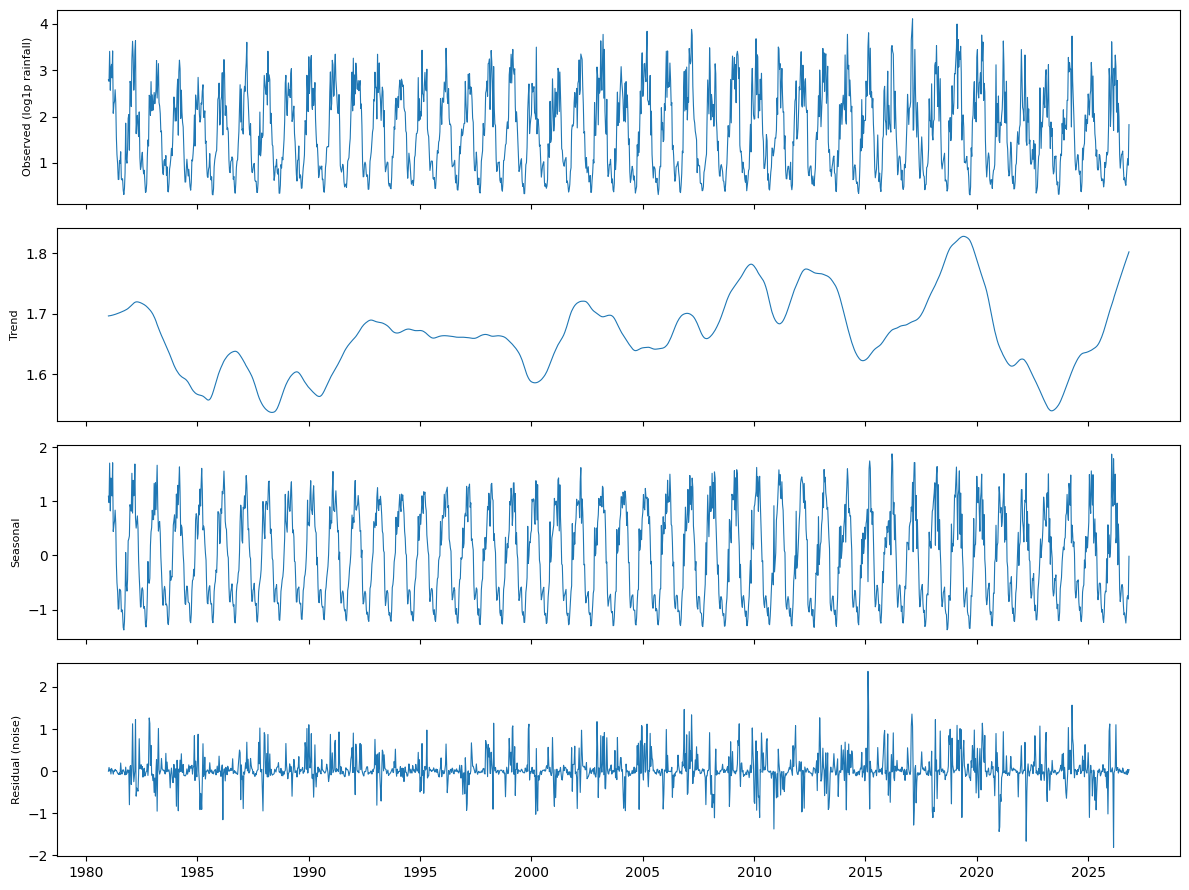

Seasonal strength: 0.832 | Trend strength: 0.039


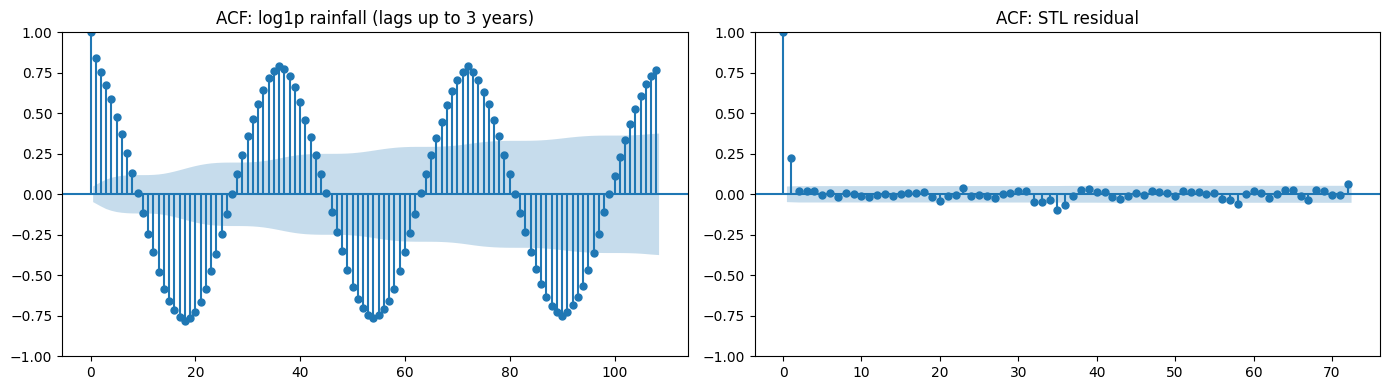

lag  1: raw=+0.839  residual=+0.223
lag  2: raw=+0.753  residual=+0.022
lag  3: raw=+0.673  residual=+0.019
lag 12: raw=-0.359  residual=-0.004
lag 18: raw=-0.780  residual=+0.013
lag 36: raw=+0.793  residual=-0.066


In [4]:

# log1p because rainfall is right-skewed and near 0 in summer
y = pd.Series(np.log1p(nat["rfh"].values))   # regular integer index, period = 36 dekads/year

res = STL(y, period=36, robust=True).fit()

# --- decomposition plot ---
fig, ax = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
comps = [("Observed (log1p rainfall)", y), ("Trend", res.trend),
         ("Seasonal", res.seasonal), ("Residual (noise)", res.resid)]
for a, (title, s) in zip(ax, comps):
    a.plot(nat.index, s.values, lw=0.8)
    a.set_ylabel(title, fontsize=8)
plt.tight_layout()
plt.savefig("decomposition.png", dpi=150)
plt.show()

# --- strength of trend / seasonality (Wang et al. style measures) ---
Fs = max(0, 1 - res.resid.var() / (res.seasonal + res.resid).var())
Ft = max(0, 1 - res.resid.var() / (res.trend + res.resid).var())
print(f"Seasonal strength: {Fs:.3f} | Trend strength: {Ft:.3f}")

# --- ACF of raw (log) series and of the residual ---
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(y, lags=108, ax=ax[0], title="ACF: log1p rainfall (lags up to 3 years)")
plot_acf(res.resid, lags=72, ax=ax[1], title="ACF: STL residual")
plt.tight_layout()
plt.savefig("acf.png", dpi=150)
plt.show()

from statsmodels.tsa.stattools import acf
a_raw = acf(y, nlags=36)
a_res = acf(res.resid, nlags=36)
for k in [1, 2, 3, 12, 18, 36]:
    print(f"lag {k:>2}: raw={a_raw[k]:+.3f}  residual={a_res[k]:+.3f}")

In [7]:


print(f"Seasonal strength: {Fs:.3f} | Trend strength: {Ft:.3f}\n")

# chronological 70/15/15 split (no shuffling)
dates = nat.index
n = len(y)
n_tr = int(0.70 * n)
n_va = int(0.15 * n)
tr = slice(0, n_tr)
va = slice(n_tr, n_tr + n_va)
te = slice(n_tr + n_va, n)

for name, s in [("train", tr), ("val", va), ("test", te)]:
    print(f"{name:5s}: {dates[s][0].date()} -> {dates[s][-1].date()}  ({len(dates[s])} dekads)")

# unit-root / stationarity tests on TRAIN only
ytr = y.iloc[tr]

def tests(s, label):
    adf_p = adfuller(s, autolag="AIC")[1]
    kpss_p = kpss(s, regression="c", nlags="auto")[1]
    print(f"{label:34s} ADF p={adf_p:.4f} | KPSS p={kpss_p:.4f}")

print()
tests(ytr, "train, log1p")
tests(ytr.diff(36).dropna(), "train, seasonal diff (lag 36)")
tests(ytr.diff().dropna(), "train, first diff")

Seasonal strength: 0.832 | Trend strength: 0.039

train: 1981-01-01 -> 2013-01-21  (1155 dekads)
val  : 2013-02-01 -> 2019-12-01  (247 dekads)
test : 2019-12-11 -> 2026-11-01  (249 dekads)

train, log1p                       ADF p=0.0000 | KPSS p=0.1000
train, seasonal diff (lag 36)      ADF p=0.0000 | KPSS p=0.1000
train, first diff                  ADF p=0.0000 | KPSS p=0.1000


In [9]:

yv = y.values
n_te0 = n_tr + n_va
idx = np.arange(n_te0, n)                      # test positions
slot = np.array([(d.month - 1) * 3 + min((d.day - 1) // 10, 2) for d in dates])  # 0..35

# climatology from TRAIN only (log scale, one mean per dekad-of-year)
clim_log = np.array([yv[:n_tr][slot[:n_tr] == k].mean() for k in range(36)])
anom = yv - clim_log[slot]
a = anom[:n_tr]
phi = (a[1:] * a[:-1]).sum() / (a[:-1] ** 2).sum()   # AR(1) on anomalies, fitted on train
print(f"AR(1) coefficient on seasonal anomalies (train): phi = {phi:.3f}\n")

preds_log = {
    "Climatology (train)":          clim_log[slot[idx]],
    "Persistence (t-1)":            yv[idx - 1],
    "Seasonal naive (t-36)":        yv[idx - 36],
    "Climatology + AR(1) anomaly":  clim_log[slot[idx]] + phi * anom[idx - 1],
}
actual = np.expm1(yv[idx])
wfp = nat["rfh_avg"].values[idx]               # WFP long-term average, already in mm

wet = np.isin(dates[idx].month, [11, 12, 1, 2, 3, 4])

def metrics(p):
    rmse = np.sqrt(mean_squared_error(actual, p))
    mae = mean_absolute_error(actual, p)
    mape_wet = np.mean(np.abs((actual[wet] - p[wet]) / actual[wet])) * 100
    smape = np.mean(2 * np.abs(actual - p) / (np.abs(actual) + np.abs(p))) * 100
    return dict(RMSE=rmse, MAE=mae, MAPE_wet=mape_wet, sMAPE=smape, R2=r2_score(actual, p))

rows = {k: metrics(np.expm1(v)) for k, v in preds_log.items()}
rows["WFP long-term avg (rfh_avg)"] = metrics(wfp)
out = pd.DataFrame(rows).T.round(3)
print(out)
print(f"\nwet-season test dekads (Nov-Apr): {wet.sum()} of {len(idx)}")

AR(1) coefficient on seasonal anomalies (train): phi = 0.267

                              RMSE    MAE  MAPE_wet   sMAPE     R2
Climatology (train)          5.665  3.132    62.617  36.814  0.472
Persistence (t-1)            7.305  4.042    67.985  47.510  0.122
Seasonal naive (t-36)        8.342  4.525    94.215  47.484 -0.145
Climatology + AR(1) anomaly  5.550  2.960    56.454  34.319  0.493
WFP long-term avg (rfh_avg)  5.765  3.383    77.685  38.672  0.453

wet-season test dekads (Nov-Apr): 123 of 249


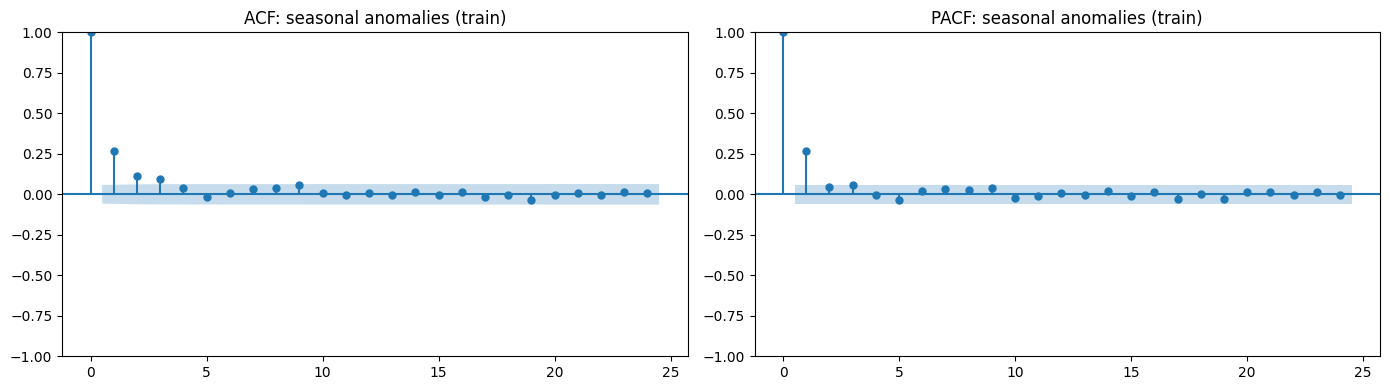

                     model      AIC      BIC  val_RMSE_log
Climatology (zero anomaly)      NaN      NaN        0.4497
                     AR(1) 725.9625 736.0662        0.4273
                     AR(2) 725.8621 741.0177        0.4278
                     AR(3) 723.6232 743.8306        0.4290
                     AR(4) 725.6062 750.8654        0.4290
                     AR(5) 726.0313 756.3425        0.4297
                     AR(6) 727.6295 762.9925        0.4289
                     MA(1) 735.2510 745.3547        0.4291
                     MA(2) 731.0458 746.2013        0.4276
                     MA(3) 725.2269 745.4343        0.4291
                     MA(4) 724.1446 749.4038        0.4297
                     MA(5) 725.3973 755.7084        0.4295
                     MA(6) 727.1756 762.5386        0.4301


In [10]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA

atr = anom[:n_tr]
ava = anom[n_tr:n_tr + n_va]

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(atr, lags=24, ax=ax[0], title="ACF: seasonal anomalies (train)")
plot_pacf(atr, lags=24, ax=ax[1], method="ywm", title="PACF: seasonal anomalies (train)")
plt.tight_layout()
plt.savefig("acf_pacf_anomaly.png", dpi=150)
plt.show()

rows = [dict(model="Climatology (zero anomaly)", AIC=np.nan, BIC=np.nan,
             val_RMSE_log=np.sqrt(np.mean(ava ** 2)))]
for kind in ["AR", "MA"]:
    for k in range(1, 7):
        order = (k, 0, 0) if kind == "AR" else (0, 0, k)
        m = ARIMA(atr, order=order, trend="n").fit()
        full = m.apply(anom)                       # parameters fixed from train
        err = ava - full.fittedvalues[n_tr:n_tr + n_va]   # one-step-ahead on validation
        rows.append(dict(model=f"{kind}({k})", AIC=m.aic, BIC=m.bic,
                         val_RMSE_log=np.sqrt(np.mean(err ** 2))))

print(pd.DataFrame(rows).round(4).to_string(index=False))

AR(1) params: [0.267 0.109]
MA(2) params: [0.252 0.069 0.11 ]
MA(3) params: [0.249 0.091 0.084 0.109]

                              RMSE    MAE  MAPE_wet   sMAPE     R2
Climatology (train)          5.665  3.132    62.617  36.814  0.472
Climatology + AR(1) anomaly  5.550  2.960    56.454  34.319  0.493
AR(1)                        5.550  2.960    56.454  34.319  0.493
MA(2)                        5.544  2.966    56.694  34.382  0.494
MA(3)                        5.601  2.982    57.037  34.637  0.484


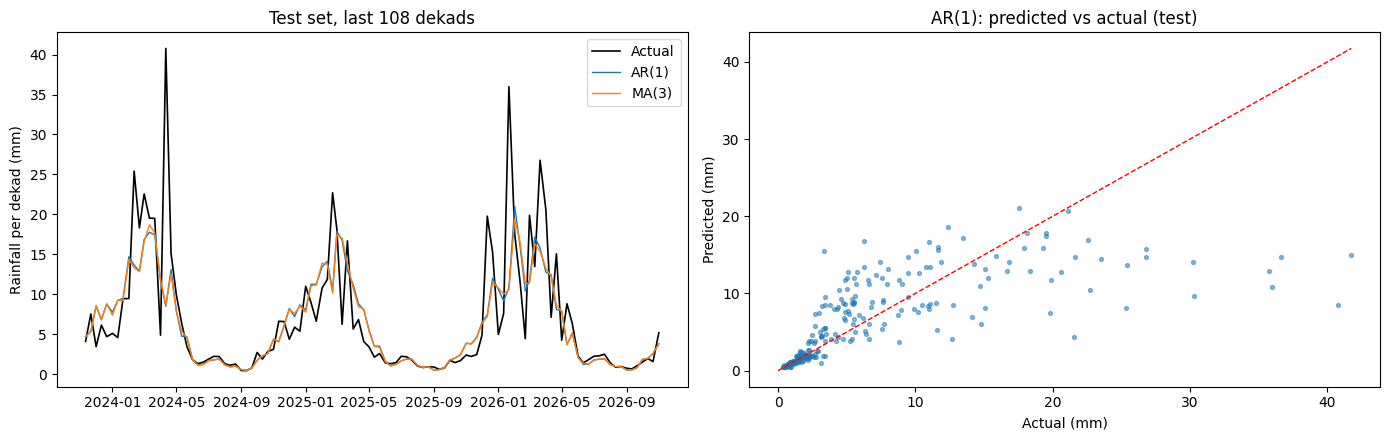

In [11]:
res_models = {}
for name, order in [("AR(1)", (1, 0, 0)), ("MA(2)", (0, 0, 2)), ("MA(3)", (0, 0, 3))]:
    m = ARIMA(atr, order=order, trend="n").fit()
    fa = np.asarray(m.apply(anom).fittedvalues)       # one-step-ahead, params fixed from train
    res_models[name] = np.expm1(clim_log[slot[idx]] + fa[idx])
    print(name, "params:", np.round(m.params, 3))

new = pd.DataFrame({k: metrics(v) for k, v in res_models.items()}).T.round(3)
print()
print(pd.concat([out.loc[["Climatology (train)", "Climatology + AR(1) anomaly"]], new]))

# --- predicted vs actual: last 3 years + scatter ---
d_te = dates[idx]
last = slice(-108, None)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(d_te[last], actual[last], "k", lw=1.2, label="Actual")
ax[0].plot(d_te[last], res_models["AR(1)"][last], lw=1, label="AR(1)")
ax[0].plot(d_te[last], res_models["MA(3)"][last], lw=1, label="MA(3)")
ax[0].set_ylabel("Rainfall per dekad (mm)")
ax[0].set_title("Test set, last 108 dekads")
ax[0].legend()
ax[1].scatter(actual, res_models["AR(1)"], s=8, alpha=0.5)
lim = max(actual.max(), res_models["AR(1)"].max())
ax[1].plot([0, lim], [0, lim], "r--", lw=1)
ax[1].set_xlabel("Actual (mm)")
ax[1].set_ylabel("Predicted (mm)")
ax[1].set_title("AR(1): predicted vs actual (test)")
plt.tight_layout()
plt.savefig("ar_ma_test.png", dpi=150)
plt.show()

In [12]:
rows, fits = [], {}
grid = [(p, 0, q) for p in range(3) for q in range(3) if (p, q) != (0, 0)]
grid += [(1, 1, 1), (1, 1, 0), (0, 1, 1)]          # d=1 for contrast
for key in grid:
    m = ARIMA(atr, order=key, trend="n").fit()
    fa = np.asarray(m.apply(anom).fittedvalues)     # params fixed from train
    err = anom[n_tr:n_tr + n_va] - fa[n_tr:n_tr + n_va]
    rows.append(dict(key=key, AIC=m.aic, BIC=m.bic, val_RMSE_log=np.sqrt(np.mean(err ** 2))))
    fits[key] = fa

tab = pd.DataFrame(rows)
print(tab.round(4).to_string(index=False))

best = min((r for r in rows if r["key"][1] == 0), key=lambda r: r["BIC"])["key"]
print("\nBest d=0 order by BIC:", best)

cmp = {}
for key in [best, (1, 1, 1)]:
    cmp[f"ARIMA{key}"] = np.expm1(clim_log[slot[idx]] + fits[key][idx])
print()
print(pd.DataFrame({k: metrics(v) for k, v in cmp.items()}).T.round(3))

# wet vs dry season error for the best model
p_best = cmp[f"ARIMA{best}"]
for nm, mask in [("wet (Nov-Apr)", wet), ("dry (May-Oct)", ~wet)]:
    r = np.sqrt(np.mean((actual[mask] - p_best[mask]) ** 2))
    print(f"RMSE {nm}: {r:.3f} mm over {mask.sum()} dekads")

      key       AIC       BIC  val_RMSE_log
(0, 0, 1)  735.2510  745.3547        0.4291
(0, 0, 2)  731.0458  746.2013        0.4276
(1, 0, 0)  725.9625  736.0662        0.4273
(1, 0, 1)  724.6147  739.7703        0.4285
(1, 0, 2)  725.2484  745.4558        0.4280
(2, 0, 0)  725.8621  741.0177        0.4278
(2, 0, 1)  725.6568  745.8642        0.4280
(2, 0, 2)  726.5534  751.8127        0.4284
(1, 1, 1)  733.1790  748.3320        0.4231
(1, 1, 0) 1057.7579 1067.8599        0.4965
(0, 1, 1)  808.4369  818.5389        0.4408

Best d=0 order by BIC: (1, 0, 0)

                 RMSE    MAE  MAPE_wet   sMAPE     R2
ARIMA(1, 0, 0)  5.550  2.960    56.454  34.319  0.493
ARIMA(1, 1, 1)  5.525  2.998    59.341  34.909  0.498
RMSE wet (Nov-Apr): 7.761 mm over 123 dekads
RMSE dry (May-Oct): 1.439 mm over 126 dekads


ARIMA(1,1,1) params [ar, ma, sigma2]: [ 0.264 -0.996  0.11 ] 

SARIMA(1,0,0)(1,0,0,36) on log1p: 36s, converged=True
Fourier(K=4) + AR(1) errors: 2s, converged=True

                                   RMSE    MAE  MAPE_wet   sMAPE     R2
SARIMA(1,0,0)(1,0,0,36) on log1p  6.453  3.409    54.158  43.522  0.315
Fourier(K=4) + AR(1) errors       5.593  3.032    58.585  37.838  0.485
ARIMA(1,0,0) on anomalies         5.550  2.960    56.454  34.319  0.493
Climatology (train)               5.665  3.132    62.617  36.814  0.472


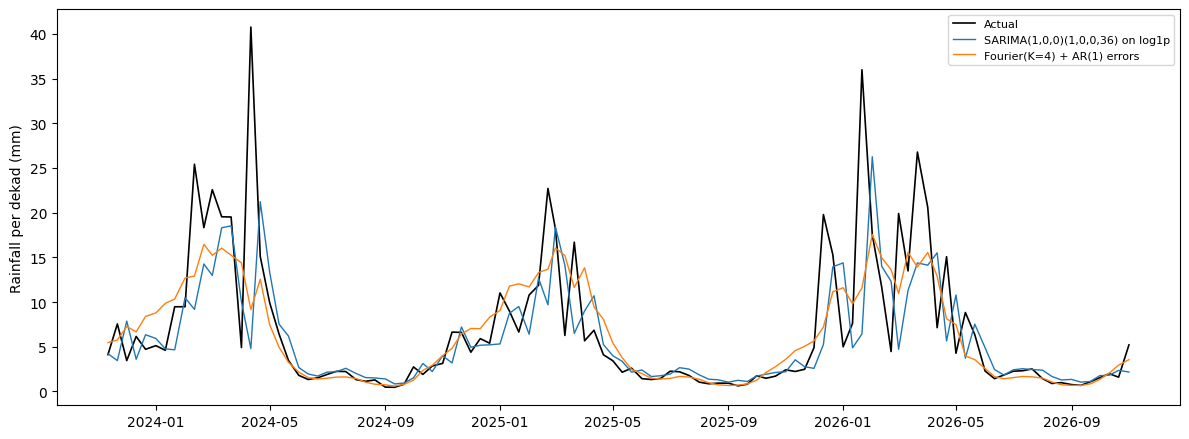

In [13]:
import time
from statsmodels.tsa.statespace.sarimax import SARIMAX

# (a) check the MA term of ARIMA(1,1,1)
m111 = ARIMA(atr, order=(1, 1, 1), trend="n").fit()
print("ARIMA(1,1,1) params [ar, ma, sigma2]:", np.round(m111.params, 3), "\n")

# (b) Fourier terms for the yearly cycle (K = 4 harmonics)
K = 4
ang = 2 * np.pi * slot / 36
X = np.column_stack([f(k * ang) for k in range(1, K + 1) for f in (np.sin, np.cos)])

specs = {
    "SARIMA(1,0,0)(1,0,0,36) on log1p": dict(exog=None,
        kw=dict(order=(1, 0, 0), seasonal_order=(1, 0, 0, 36), trend="c")),
    "Fourier(K=4) + AR(1) errors": dict(exog=X,
        kw=dict(order=(1, 0, 0), trend="c")),
}
sar = {}
for name, s in specs.items():
    t0 = time.time()
    ex = None if s["exog"] is None else s["exog"][:n_tr]
    m = SARIMAX(yv[:n_tr], exog=ex, **s["kw"]).fit(disp=False, maxiter=200)
    ap = m.apply(yv, exog=s["exog"])                 # params fixed from train
    sar[name] = np.expm1(np.asarray(ap.fittedvalues)[idx])
    print(f"{name}: {time.time()-t0:.0f}s, converged={m.mle_retvals.get('converged')}")

tab = pd.DataFrame({k: metrics(v) for k, v in sar.items()}).T
tab = pd.concat([tab,
                 pd.DataFrame({"ARIMA(1,0,0) on anomalies": metrics(res_models["AR(1)"])}).T,
                 out.loc[["Climatology (train)"]]])
print()
print(tab.round(3))

# predicted vs actual, last 108 test dekads
plt.figure(figsize=(12, 4.5))
plt.plot(dates[idx][-108:], actual[-108:], "k", lw=1.2, label="Actual")
for k, v in sar.items():
    plt.plot(dates[idx][-108:], v[-108:], lw=1, label=k)
plt.ylabel("Rainfall per dekad (mm)")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig("sarima_test.png", dpi=150)
plt.show()

In [14]:
import torch, torch.nn as nn

sd = anom[:n_tr].std()
sin_f, cos_f = np.sin(2 * np.pi * slot / 36), np.cos(2 * np.pi * slot / 36)

def make_xy(L):
    X, Y, T = [], [], []
    for t in range(L, n):
        X.append(np.column_stack([anom[t-L:t] / sd, sin_f[t-L+1:t+1], cos_f[t-L+1:t+1]]))
        Y.append(anom[t] / sd)
        T.append(t)
    return (torch.tensor(np.array(X), dtype=torch.float32),
            torch.tensor(np.array(Y), dtype=torch.float32), np.array(T))

class Net(nn.Module):
    def __init__(self, kind, hidden, layers):
        super().__init__()
        cell = nn.RNN if kind == "RNN" else nn.LSTM
        self.rnn = cell(3, hidden, layers, batch_first=True)
        self.out = nn.Linear(hidden, 1)
    def forward(self, x):
        o, _ = self.rnn(x)
        return self.out(o[:, -1]).squeeze(-1)

def train_nn(kind, L, hidden, layers, lr, batch, max_epochs=60, patience=8):
    torch.manual_seed(0)
    X, Y, T = make_xy(L)
    itr, iva = T < n_tr, (T >= n_tr) & (T < n_te0)
    Xtr, Ytr = X[itr], Y[itr]
    net = Net(kind, hidden, layers)
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    lossf = nn.MSELoss()
    best, wait, state = np.inf, 0, None
    for ep in range(max_epochs):
        net.train()
        perm = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), batch):
            b = perm[i:i + batch]
            opt.zero_grad()
            lossf(net(Xtr[b]), Ytr[b]).backward()
            opt.step()
        net.eval()
        with torch.no_grad():
            v = torch.sqrt(lossf(net(X[iva]), Y[iva])).item() * sd   # val RMSE, log units
        if v < best - 1e-5:
            best, wait = v, 0
            state = {k: p.clone() for k, p in net.state_dict().items()}
        else:
            wait += 1
            if wait >= patience:
                break
    net.load_state_dict(state)
    return net, best, ep + 1

net, v, epochs = train_nn("RNN", L=6, hidden=16, layers=1, lr=1e-3, batch=32)
print(f"RNN (L=6, 16 units, 1 layer): val RMSE (log) = {v:.4f}, stopped after {epochs} epochs")
print("Reference on validation: AR(1) = 0.4273 | climatology = 0.4497")

RNN (L=6, 16 units, 1 layer): val RMSE (log) = 0.4257, stopped after 25 epochs
Reference on validation: AR(1) = 0.4273 | climatology = 0.4497


Best RNN: L=12, hidden=16, layers=2, lr=0.001, batch=32 -> Val RMSE (log) = 0.4247
Best LSTM: L=36, hidden=16, layers=1, lr=0.001, batch=32 -> Val RMSE (log) = 0.4253

--- Validation Tuning Results ---
Model  Lag (L)  Hidden  Layers     LR  Batch  Val_RMSE_log  Epochs
  RNN        6      16       1 0.0010     32        0.4257      25
  RNN       12      16       1 0.0010     32        0.4255      31
  RNN       36      16       1 0.0010     32        0.4252      26
  RNN       12      32       1 0.0010     32        0.4278      16
  RNN       12      16       2 0.0010     32        0.4247      17
  RNN       12      16       1 0.0005     16        0.4257      31
 LSTM        6      16       1 0.0010     32        0.4266      30
 LSTM       12      16       1 0.0010     32        0.4262      30
 LSTM       36      16       1 0.0010     32        0.4253      38
 LSTM       12      32       1 0.0010     32        0.4280      17
 LSTM       12      16       2 0.0010     32        0.4254   

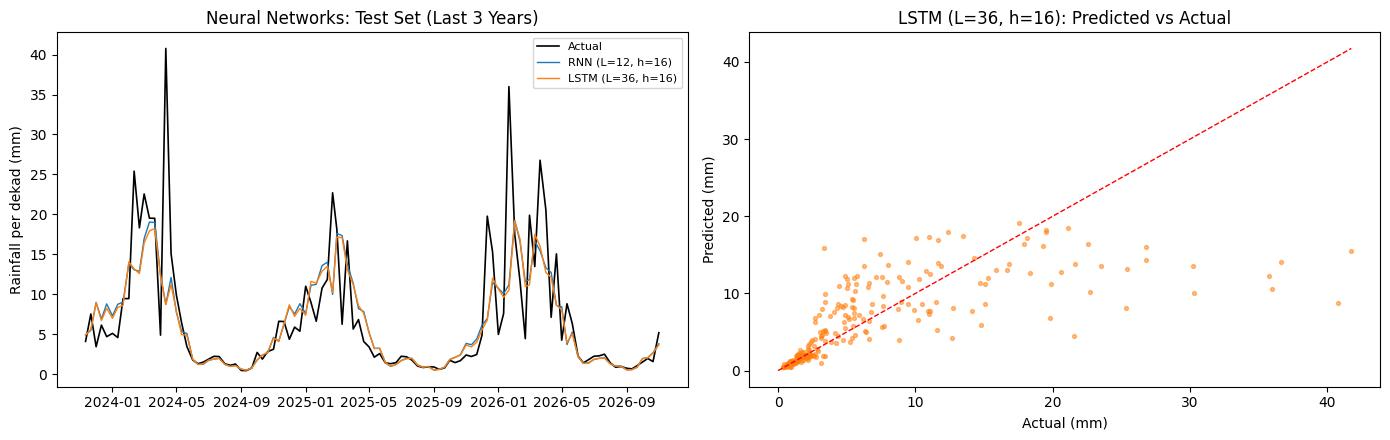

In [16]:
# --- Cell 11: Tasks 10 & 11 - Hyperparameter Tuning for RNN and LSTM ---

# Define a focused grid covering all 5 required hyperparameters:
# (lag_size L, hidden_units, num_layers, learning_rate, batch_size)
param_grid = [
    (6,  16, 1, 1e-3, 32),
    (12, 16, 1, 1e-3, 32),
    (36, 16, 1, 1e-3, 32),   # 1 full year lookback
    (12, 32, 1, 1e-3, 32),   # more neurons
    (12, 16, 2, 1e-3, 32),   # 2 layers
    (12, 16, 1, 5e-4, 16),   # smaller lr & batch size
]

tuning_results = []
best_models = {}

for kind in ["RNN", "LSTM"]:
    best_val = np.inf
    best_cfg = None
    best_net = None

    for (L, hid, lay, lr, bs) in param_grid:
        net, val_rmse, ep = train_nn(kind, L=L, hidden=hid, layers=lay, lr=lr, batch=bs)
        tuning_results.append({
            "Model": kind, "Lag (L)": L, "Hidden": hid, "Layers": lay,
            "LR": lr, "Batch": bs, "Val_RMSE_log": round(val_rmse, 4), "Epochs": ep
        })
        if val_rmse < best_val:
            best_val = val_rmse
            best_cfg = (L, hid, lay, lr, bs)
            best_net = net

    best_models[kind] = (best_net, best_cfg, best_val)
    print(f"Best {kind}: L={best_cfg[0]}, hidden={best_cfg[1]}, layers={best_cfg[2]}, "
          f"lr={best_cfg[3]}, batch={best_cfg[4]} -> Val RMSE (log) = {best_val:.4f}")

# Print full tuning table for your report
tuning_df = pd.DataFrame(tuning_results)
print("\n--- Validation Tuning Results ---")
print(tuning_df.to_string(index=False))

# Evaluate best RNN and best LSTM on the TEST set (in mm)
nn_test_preds = {}
for kind, (net, cfg, _) in best_models.items():
    L = cfg[0]
    X_all, _, T_all = make_xy(L)
    test_mask = T_all >= n_te0
    net.eval()
    with torch.no_grad():
        pred_anom_log = net(X_all[test_mask]).numpy() * sd
    pred_mm = np.expm1(clim_log[slot[idx]] + pred_anom_log)
    nn_test_preds[f"{kind} (L={L}, h={cfg[1]})"] = pred_mm

nn_metrics = pd.DataFrame({k: metrics(v) for k, v in nn_test_preds.items()}).T.round(3)
print("\n--- Test Set Comparison (All Models in mm) ---")
all_results = pd.concat([
    out.loc[["Climatology (train)", "WFP long-term avg (rfh_avg)"]],
    new.loc[["AR(1)", "MA(2)"]],
    nn_metrics
])
print(all_results)

# Plot Test Predictions: Best RNN & Best LSTM vs Actual (last 108 dekads)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
d_te = dates[idx]
last = slice(-108, None)

ax[0].plot(d_te[last], actual[last], "k", lw=1.2, label="Actual")
for label, pred in nn_test_preds.items():
    ax[0].plot(d_te[last], pred[last], lw=1, label=label)
ax[0].set_ylabel("Rainfall per dekad (mm)")
ax[0].set_title("Neural Networks: Test Set (Last 3 Years)")
ax[0].legend(fontsize=8)

best_lstm_label = [k for k in nn_test_preds if "LSTM" in k][0]
best_lstm_pred = nn_test_preds[best_lstm_label]
ax[1].scatter(actual, best_lstm_pred, s=8, alpha=0.5, color="tab:orange")
lim = max(actual.max(), best_lstm_pred.max())
ax[1].plot([0, lim], [0, lim], "r--", lw=1)
ax[1].set_xlabel("Actual (mm)")
ax[1].set_ylabel("Predicted (mm)")
ax[1].set_title(f"{best_lstm_label}: Predicted vs Actual")

plt.tight_layout()
plt.savefig("rnn_lstm_test.png", dpi=150)
plt.show()


Lower Quantile LSTM (q=0.025): stopped at epoch 23, val pinball=0.0525
Upper Quantile LSTM (q=0.975): stopped at epoch 34, val pinball=0.0780

--- 95% Prediction Interval Evaluation (Test Set) ---
Raw Quantile LSTM Pair (95%)     | PICP:  88.4% (Wet:  85.4%) | MPIW: 12.25 mm (Wet: 22.07 mm)
Conformalized Quantile LSTM      | PICP:  94.0% (Wet:  90.2%) | MPIW: 14.81 mm (Wet: 26.30 mm)


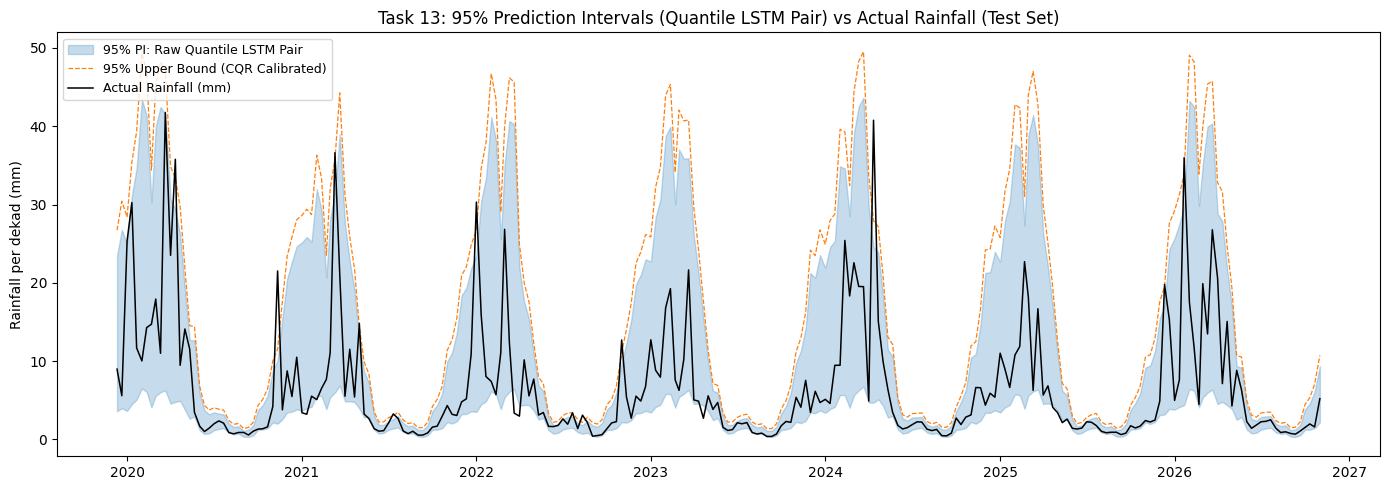

In [17]:
# --- Cell 12: Task 13 - Pair of Quantile LSTMs (2.5% and 97.5%) ---

def pinball_loss(y_pred, y_true, q):
    err = y_true - y_pred
    return torch.mean(torch.maximum(q * err, (q - 1.0) * err))

def train_quantile_lstm(q, L=36, hidden=16, layers=1, lr=1e-3, batch=32, max_epochs=80, patience=12):
    torch.manual_seed(42)
    X, Y, T = make_xy(L)
    itr, iva = T < n_tr, (T >= n_tr) & (T < n_te0)
    Xtr, Ytr = X[itr], Y[itr]

    net = Net("LSTM", hidden, layers)
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    best_loss, wait, state = np.inf, 0, None

    for ep in range(max_epochs):
        net.train()
        perm = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), batch):
            b = perm[i:i + batch]
            opt.zero_grad()
            loss = pinball_loss(net(Xtr[b]), Ytr[b], q)
            loss.backward()
            opt.step()

        net.eval()
        with torch.no_grad():
            val_loss = pinball_loss(net(X[iva]), Y[iva], q).item()
        if val_loss < best_loss - 1e-5:
            best_loss, wait = val_loss, 0
            state = {k: p.clone() for k, p in net.state_dict().items()}
        else:
            wait += 1
            if wait >= patience:
                break

    net.load_state_dict(state)
    return net, best_loss, ep + 1

# Train two separate LSTM models: lower (2.5%) and upper (97.5%)
L_q = 36
lstm_low, loss_low, ep_low = train_quantile_lstm(0.025, L=L_q)
lstm_high, loss_high, ep_high = train_quantile_lstm(0.975, L=L_q)
print(f"Lower Quantile LSTM (q=0.025): stopped at epoch {ep_low}, val pinball={loss_low:.4f}")
print(f"Upper Quantile LSTM (q=0.975): stopped at epoch {ep_high}, val pinball={loss_high:.4f}")

# Predict on Validation and Test sets
X_all, _, T_all = make_xy(L_q)
val_mask = (T_all >= n_tr) & (T_all < n_te0)
test_mask = T_all >= n_te0

lstm_low.eval()
lstm_high.eval()
with torch.no_grad():
    low_val_log = lstm_low(X_all[val_mask]).numpy() * sd
    high_val_log = lstm_high(X_all[val_mask]).numpy() * sd
    low_test_log = lstm_low(X_all[test_mask]).numpy() * sd
    high_test_log = lstm_high(X_all[test_mask]).numpy() * sd

# Raw (uncalibrated) 95% intervals in mm
idx_va = np.arange(n_tr, n_te0)
lower_raw = np.maximum(0.0, np.expm1(clim_log[slot[idx]] + low_test_log))
upper_raw = np.maximum(lower_raw, np.expm1(clim_log[slot[idx]] + high_test_log))

# Conformalized Quantile Regression (CQR) calibration using validation residuals
val_anom = anom[idx_va]
cal_scores = np.maximum(low_val_log - val_anom, val_anom - high_val_log)
q_hat = np.quantile(cal_scores, 0.95 * (1 + 1 / len(val_anom)))

lower_cqr = np.maximum(0.0, np.expm1(clim_log[slot[idx]] + low_test_log - q_hat))
upper_cqr = np.maximum(lower_cqr, np.expm1(clim_log[slot[idx]] + high_test_log + q_hat))

def eval_intervals(y_true, lo, hi, label):
    inside = (y_true >= lo) & (y_true <= hi)
    picp = np.mean(inside) * 100
    mpiw = np.mean(hi - lo)
    picp_wet = np.mean(inside[wet]) * 100
    mpiw_wet = np.mean((hi - lo)[wet])
    print(f"{label:32s} | PICP: {picp:5.1f}% (Wet: {picp_wet:5.1f}%) | MPIW: {mpiw:5.2f} mm (Wet: {mpiw_wet:5.2f} mm)")
    return picp, mpiw

print("\n--- 95% Prediction Interval Evaluation (Test Set) ---")
eval_intervals(actual, lower_raw, upper_raw, "Raw Quantile LSTM Pair (95%)")
eval_intervals(actual, lower_cqr, upper_cqr, "Conformalized Quantile LSTM")

# Plot 95% Prediction Intervals against Actual Values (Test Set)
fig, ax = plt.subplots(figsize=(14, 5))
d_te = dates[idx]

ax.fill_between(d_te, lower_raw, upper_raw, color="tab:blue", alpha=0.25, label="95% PI: Raw Quantile LSTM Pair")
ax.plot(d_te, upper_cqr, color="tab:orange", ls="--", lw=0.9, label="95% Upper Bound (CQR Calibrated)")
ax.plot(d_te, actual, "k", lw=1.1, label="Actual Rainfall (mm)")

ax.set_ylabel("Rainfall per dekad (mm)")
ax.set_title("Task 13: 95% Prediction Intervals (Quantile LSTM Pair) vs Actual Rainfall (Test Set)")
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.savefig("quantile_lstm_intervals.png", dpi=150)
plt.show()


Test Period (2019-12-11 to 2026-11-01, 249 dekads):
  Observed Spring Flood-Risk Dekads (>22 mm in Mar-May): 8
  Observed Wet-Season Severe Dry Dekads (<50% normal):   16

--- Flood Anticipatory Action: Cost-Loss & Risk Table (Test Set, L=$10M, C=$1.5M) ---
                      Decision Policy  Triggers  Hits  Misses (Risk)  False Alarms  Hit Rate (%)  Total Cost ($M)  Net Savings ($M)
       1. Never Act (Reactive Relief)         0     0              8             0           0.0             80.0               0.0
    2. Always Act in Spring (Blanket)        63     8              0            55         100.0            118.5             -38.5
      3. Point LSTM Forecast (>18 mm)         2     0              8             2           0.0             83.0              -3.0
       4. Raw Quantile Upper (>25 mm)        30     7              1            23          87.5             76.0               4.0
5. CQR Quantile Upper (>28 mm) [Rec.]        30     7              1            23

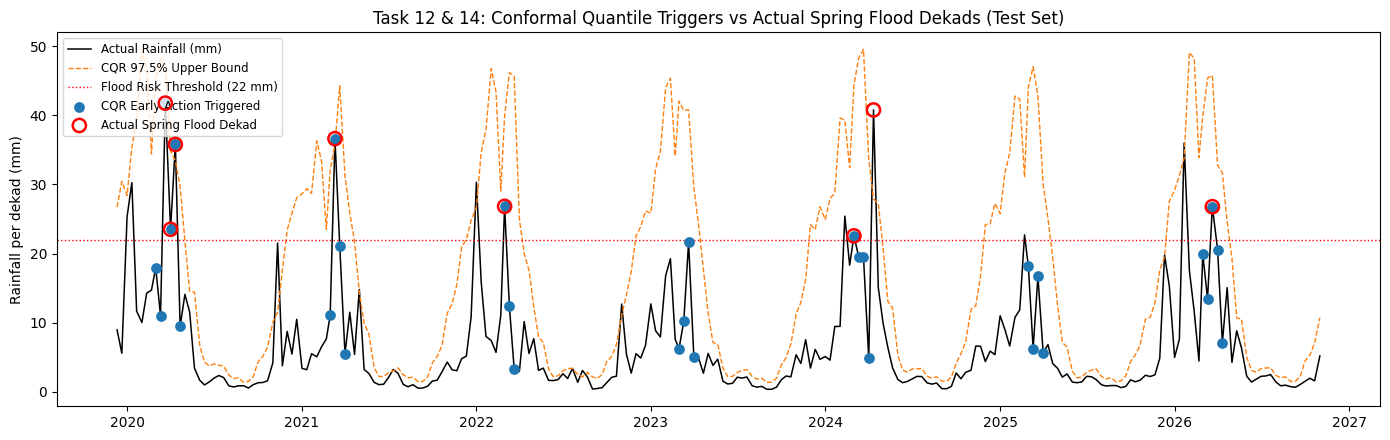

In [18]:
# --- Cell 13: Tasks 12 & 14 - Forecast-to-Action Decision Layer & Cost-Loss Analysis ---

# 1. Define Anticipatory Action Scenarios on the Test Set (249 dekads: Dec 2019 - Nov 2026)
months_te = dates[idx].month
spring_mask = np.isin(months_te, [3, 4, 5])          # Spring flood window (Mar-May)
wet_mask = np.isin(months_te, [11, 12, 1, 2, 3, 4]) # Wet season agricultural window (Nov-Apr)

# Real-world disaster thresholds (national area-weighted mm per dekad):
# Extreme flood event: actual rainfall > 22 mm/dekad in spring (top ~10% of spring dekads)
flood_event = spring_mask & (actual > 22.0)

# Severe wet-season dry spell: actual rainfall < 50% of normal climatology when normal >= 10 mm
clim_mm = np.expm1(clim_log[slot[idx]])
drought_event = wet_mask & (clim_mm >= 10.0) & (actual < 0.5 * clim_mm)

print(f"Test Period ({dates[idx][0].date()} to {dates[idx][-1].date()}, {len(idx)} dekads):")
print(f"  Observed Spring Flood-Risk Dekads (>22 mm in Mar-May): {flood_event.sum()}")
print(f"  Observed Wet-Season Severe Dry Dekads (<50% normal):   {drought_event.sum()}\n")

# 2. Compare Decision Policies for Flood Early Action (Pre-positioning relief stocks)
# Policy A: Never Act
# Policy B: Always Act during Spring (Mar-May)
# Policy C: Point LSTM Trigger (act if point forecast > 18 mm)
# Policy D: Raw Quantile LSTM Upper Bound Trigger (act if 97.5% upper bound > 25 mm)
# Policy E: Conformal Quantile LSTM Upper Bound Trigger (act if CQR upper bound > 28 mm)

policies = {
    "1. Never Act (Reactive Relief)":         np.zeros_like(flood_event, dtype=bool),
    "2. Always Act in Spring (Blanket)":      spring_mask,
    "3. Point LSTM Forecast (>18 mm)":        spring_mask & (best_lstm_pred > 18.0),
    "4. Raw Quantile Upper (>25 mm)":         spring_mask & (upper_raw > 25.0),
    "5. CQR Quantile Upper (>28 mm) [Rec.]":  spring_mask & (upper_cqr > 28.0),
}

# Standard Anticipatory Action Economics (WFP/FAO benchmarks):
# Suppose unmitigated flood damage per severe dekad = $10.0M (Loss L = 10.0)
# Early action pre-positioning cost = $1.5M (Cost C = 1.5, C/L = 0.15), reducing damage by 70% ($7.0M avoided loss)
L_damage = 10.0   # $ Million unmitigated loss per flood dekad
C_action = 1.5    # $ Million early-action mobilization cost
mitigation_eff = 0.70  # 70% of loss avoided when early action is taken in time

policy_rows = []
for name, trigger in policies.items():
    hits = np.sum(trigger & flood_event)            # True Positives (timely early action)
    false_alarms = np.sum(trigger & ~flood_event)   # False Positives (unnecessary mobilization)
    misses = np.sum(~trigger & flood_event)         # False Negatives (unmitigated disaster!)

    # Total economic burden ($M) over the 7-year test window:
    # Cost of all actions + residual damage on hits + full damage on misses
    total_cost = (hits + false_alarms) * C_action + hits * L_damage * (1 - mitigation_eff) + misses * L_damage
    baseline_cost = np.sum(flood_event) * L_damage  # Cost of Never Acting
    net_savings = baseline_cost - total_cost

    pod = (hits / flood_event.sum() * 100) if flood_event.sum() > 0 else 0
    far = (false_alarms / trigger.sum() * 100) if trigger.sum() > 0 else 0

    policy_rows.append({
        "Decision Policy": name,
        "Triggers": int(trigger.sum()),
        "Hits": int(hits),
        "Misses (Risk)": int(misses),
        "False Alarms": int(false_alarms),
        "Hit Rate (%)": round(pod, 1),
        "Total Cost ($M)": round(total_cost, 2),
        "Net Savings ($M)": round(net_savings, 2),
    })

policy_df = pd.DataFrame(policy_rows)
print("--- Flood Anticipatory Action: Cost-Loss & Risk Table (Test Set, L=$10M, C=$1.5M) ---")
print(policy_df.to_string(index=False))

# 3. Sensitivity Analysis across Cost-to-Loss Ratios (C/L = 0.10, 0.15, 0.25, 0.35)
print("\n--- Sensitivity Analysis: Net Savings ($M) vs Never Acting across C/L Ratios ---")
sens_rows = []
for cl in [0.10, 0.15, 0.25, 0.35]:
    c_val = cl * L_damage
    row = {"C/L Ratio": cl, "Action Cost ($M)": round(c_val, 2)}
    for name, trigger in list(policies.items())[1:]:
        hits = np.sum(trigger & flood_event)
        fa = np.sum(trigger & ~flood_event)
        misses = np.sum(~trigger & flood_event)
        tot = (hits + fa) * c_val + hits * L_damage * (1 - mitigation_eff) + misses * L_damage
        row[name.split(". ")[1]] = round((np.sum(flood_event) * L_damage) - tot, 2)
    sens_rows.append(row)

print(pd.DataFrame(sens_rows).to_string(index=False))

# 4. Plot Decision Triggers vs Actual Spring Flood Events
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(d_te, actual, "k", lw=1.1, label="Actual Rainfall (mm)")
ax.plot(d_te, upper_cqr, color="tab:orange", ls="--", lw=1.0, label="CQR 97.5% Upper Bound")
ax.axhline(22.0, color="red", ls=":", lw=1.0, label="Flood Risk Threshold (22 mm)")

# Highlight CQR triggers and actual flood events
cqr_trig = policies["5. CQR Quantile Upper (>28 mm) [Rec.]"]
ax.scatter(d_te[cqr_trig], actual[cqr_trig], color="tab:blue", s=45, zorder=5, label="CQR Early Action Triggered")
ax.scatter(d_te[flood_event], actual[flood_event], facecolors="none", edgecolors="red", s=90, lw=1.8, zorder=6, label="Actual Spring Flood Dekad")

ax.set_ylabel("Rainfall per dekad (mm)")
ax.set_title("Task 12 & 14: Conformal Quantile Triggers vs Actual Spring Flood Dekads (Test Set)")
ax.legend(loc="upper left", fontsize=8.5)
plt.tight_layout()
plt.savefig("decision_triggers.png", dpi=150)
plt.show()


Available columns in dataset: ['date', 'adm_level', 'adm_id', 'PCODE', 'n_pixels', 'rfh', 'rfh_avg', 'r1h', 'r1h_avg', 'r3h', 'r3h_avg', 'rfq', 'r1q', 'r3q', 'version', 'w_rfh', 'w_avg']
Candidate identifier columns: ['PCODE']
Using column 'PCODE' with targets: [('AF32', 'Hilmand (Arid / Drought-Prone)'), ('AF17', 'Badakhshan (Highland / Flood-Prone)')]

--- Provincial CQR Quantile LSTM Generalization (Test Set) ---
                           Province P-Code  Test Mean (mm)  Test Max Spike (mm)  CQR PICP (%)  CQR MPIW (mm)
     Hilmand (Arid / Drought-Prone)   AF32            6.06                65.15          96.4          16.60
Badakhshan (Highland / Flood-Prone)   AF17            9.77                62.80          94.4          29.66


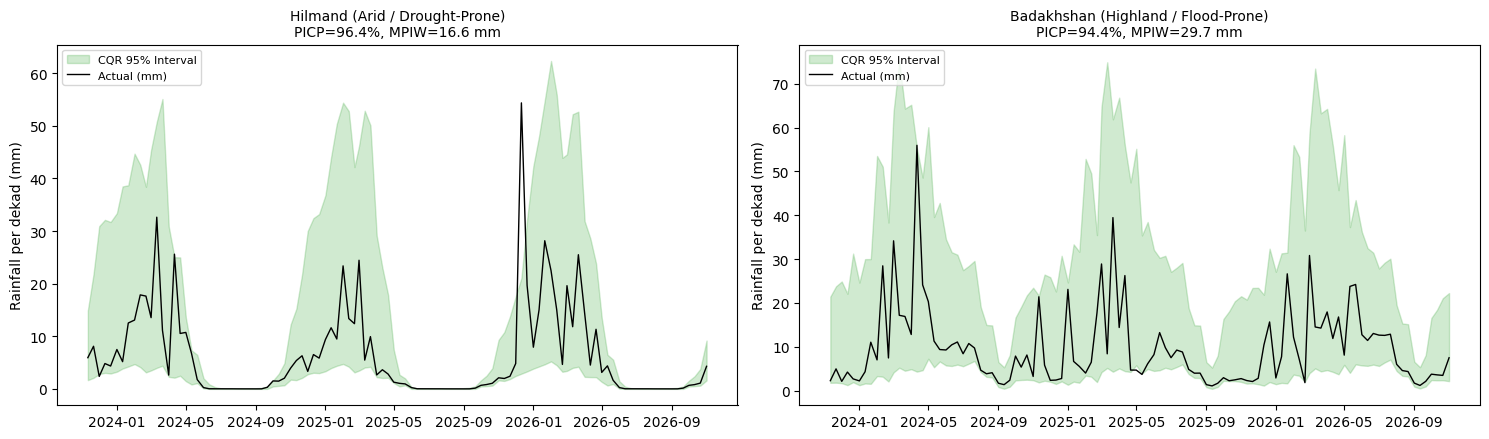

In [20]:
# --- Cell 14: Provincial Case Study (Drought-Prone Hilmand vs Flood-Prone Badakhshan) ---

print("Available columns in dataset:", list(a1.columns))

# Detect province identifier column (name or pcode)
name_cols = [c for c in a1.columns if "name" in c.lower() or "adm1" in c.lower() or "pcode" in c.lower()]
print("Candidate identifier columns:", name_cols)

# Standard HDX Afghanistan P-codes: AF32 = Hilmand (Helmand), AF17 = Badakhshan
if any("pcode" in c.lower() for c in a1.columns):
    id_col = [c for c in a1.columns if "pcode" in c.lower()][0]
    targets = [("AF32", "Hilmand (Arid / Drought-Prone)"), ("AF17", "Badakhshan (Highland / Flood-Prone)")]
else:
    id_col = [c for c in a1.columns if a1[c].dtype == "object" and c not in ["date", "version"]][0]
    vals = a1[id_col].astype(str).unique()
    h_val = [v for v in vals if "hilmand" in v.lower() or "helmand" in v.lower() or "af32" in v.lower()][0]
    b_val = [v for v in vals if "badakhshan" in v.lower() or "af17" in v.lower()][0]
    targets = [(h_val, "Hilmand (Arid / Drought-Prone)"), (b_val, "Badakhshan (Highland / Flood-Prone)")]

print(f"Using column '{id_col}' with targets: {targets}\n")

prov_summary = []
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=False)

for ax_p, (pid, label) in zip(axes, targets):
    sub = a1[a1[id_col] == pid].sort_values("date").set_index("date")
    yp = np.log1p(sub["rfh"].values)

    # Province-specific training climatology & standardized anomalies
    clim_p = np.array([yp[:n_tr][slot[:n_tr] == k].mean() for k in range(36)])
    anom_p = yp - clim_p[slot]
    sd_p = anom_p[:n_tr].std()

    # Build sequences (L=36)
    L_p = 36
    Xp, Yp, Tp = [], [], []
    for t in range(L_p, len(yp)):
        Xp.append(np.column_stack([anom_p[t-L_p:t] / sd_p, sin_f[t-L_p+1:t+1], cos_f[t-L_p+1:t+1]]))
        Yp.append(anom_p[t] / sd_p)
        Tp.append(t)
    Xp = torch.tensor(np.array(Xp), dtype=torch.float32)
    Yp = torch.tensor(np.array(Yp), dtype=torch.float32)
    Tp = np.array(Tp)

    itr_p = Tp < n_tr
    iva_p = (Tp >= n_tr) & (Tp < n_te0)
    ite_p = Tp >= n_te0

    def fit_prov_q(q_val):
        torch.manual_seed(42)
        m = Net("LSTM", hidden=16, layers=1)
        opt = torch.optim.Adam(m.parameters(), lr=1e-3)
        best_l, wait, st = np.inf, 0, None
        for ep in range(80):
            m.train()
            perm = torch.randperm(itr_p.sum())
            Xtr_p, Ytr_p = Xp[itr_p], Yp[itr_p]
            for i in range(0, len(Xtr_p), 32):
                b = perm[i:i+32]
                opt.zero_grad()
                loss = pinball_loss(m(Xtr_p[b]), Ytr_p[b], q_val)
                loss.backward()
                opt.step()
            m.eval()
            with torch.no_grad():
                vl = pinball_loss(m(Xp[iva_p]), Yp[iva_p], q_val).item()
            if vl < best_l - 1e-5:
                best_l, wait = vl, 0
                st = {k: v.clone() for k, v in m.state_dict().items()}
            else:
                wait += 1
                if wait >= 12:
                    break
        m.load_state_dict(st)
        m.eval()
        with torch.no_grad():
            return m(Xp[iva_p]).numpy() * sd_p, m(Xp[ite_p]).numpy() * sd_p

    lo_va, lo_te = fit_prov_q(0.025)
    hi_va, hi_te = fit_prov_q(0.975)

    # Conformal calibration on validation set
    va_an = anom_p[n_tr:n_te0]
    scores_p = np.maximum(lo_va - va_an, va_an - hi_va)
    qhat_p = np.quantile(scores_p, 0.95 * (1 + 1 / len(va_an)))

    act_p = sub["rfh"].values[idx]
    lo_cqr_p = np.maximum(0.0, np.expm1(clim_p[slot[idx]] + lo_te - qhat_p))
    hi_cqr_p = np.maximum(lo_cqr_p, np.expm1(clim_p[slot[idx]] + hi_te + qhat_p))

    picp_p = np.mean((act_p >= lo_cqr_p) & (act_p <= hi_cqr_p)) * 100
    mpiw_p = np.mean(hi_cqr_p - lo_cqr_p)

    prov_summary.append({
        "Province": label,
        "P-Code": pid,
        "Test Mean (mm)": round(act_p.mean(), 2),
        "Test Max Spike (mm)": round(act_p.max(), 2),
        "CQR PICP (%)": round(picp_p, 1),
        "CQR MPIW (mm)": round(mpiw_p, 2),
    })

    ax_p.fill_between(d_te[-108:], lo_cqr_p[-108:], hi_cqr_p[-108:], color="tab:green", alpha=0.22, label="CQR 95% Interval")
    ax_p.plot(d_te[-108:], act_p[-108:], "k", lw=1.0, label="Actual (mm)")
    ax_p.set_title(f"{label}\nPICP={picp_p:.1f}%, MPIW={mpiw_p:.1f} mm", fontsize=10)
    ax_p.set_ylabel("Rainfall per dekad (mm)")
    ax_p.legend(loc="upper left", fontsize=8)

print("--- Provincial CQR Quantile LSTM Generalization (Test Set) ---")
print(pd.DataFrame(prov_summary).to_string(index=False))

plt.tight_layout()
plt.savefig("provincial_case_study.png", dpi=150)
plt.show()


In [22]:
# --- Cell 15: Upgraded Multivariate Quantile LSTM + Mondrian CQR + Validation-Tuned Trigger ---

# 1. Extract area-weighted 1-month (r1h) and 3-month (r3h) cumulative rainfall features from a1
a1["w_r1h"] = a1["r1h"] * a1["n_pixels"]
a1["w_r1h_avg"] = a1["r1h_avg"] * a1["n_pixels"]
a1["w_r3h"] = a1["r3h"] * a1["n_pixels"]
a1["w_r3h_avg"] = a1["r3h_avg"] * a1["n_pixels"]

g_multi = a1.groupby("date")[["w_r1h", "w_r1h_avg", "w_r3h", "w_r3h_avg", "n_pixels"]].sum()

# Fill any initial NaNs in rolling columns with 1-dekad values
r1h_nat = (g_multi["w_r1h"] / g_multi["n_pixels"]).fillna(nat["rfh"]).values
r1h_avg_nat = (g_multi["w_r1h_avg"] / g_multi["n_pixels"]).fillna(nat["rfh_avg"]).values
r3h_nat = (g_multi["w_r3h"] / g_multi["n_pixels"]).fillna(nat["rfh"]).values
r3h_avg_nat = (g_multi["w_r3h_avg"] / g_multi["n_pixels"]).fillna(nat["rfh_avg"]).values

# Log1p anomalies standardized strictly on TRAIN statistics
anom_1m = np.log1p(r1h_nat) - np.log1p(r1h_avg_nat)
anom_3m = np.log1p(r3h_nat) - np.log1p(r3h_avg_nat)
sd_1m = anom_1m[:n_tr].std()
sd_3m = anom_3m[:n_tr].std()

def make_xy_multi(L=36):
    Xm, Ym, Tm = [], [], []
    for t in range(L, n):
        Xm.append(np.column_stack([
            anom[t-L:t] / sd,
            anom_1m[t-L:t] / sd_1m,
            anom_3m[t-L:t] / sd_3m,
            sin_f[t-L+1:t+1],
            cos_f[t-L+1:t+1]
        ]))
        Ym.append(anom[t] / sd)
        Tm.append(t)
    return (torch.tensor(np.array(Xm), dtype=torch.float32),
            torch.tensor(np.array(Ym), dtype=torch.float32), np.array(Tm))

class MultiLSTM(nn.Module):
    def __init__(self, in_features=5, hidden=24, layers=1, dropout=0.1):
        super().__init__()
        self.rnn = nn.LSTM(in_features, hidden, layers, batch_first=True)
        self.drop = nn.Dropout(dropout)
        self.out = nn.Linear(hidden, 1)
    def forward(self, x):
        o, _ = self.rnn(x)
        return self.out(self.drop(o[:, -1])).squeeze(-1)

def train_multi_quantile(q, L=36, hidden=24, lr=1e-3, batch=32, max_epochs=80, patience=12):
    torch.manual_seed(42)
    Xm, Ym, Tm = make_xy_multi(L)
    itr, iva = Tm < n_tr, (Tm >= n_tr) & (Tm < n_te0)
    Xtr, Ytr = Xm[itr], Ym[itr]

    net = MultiLSTM(in_features=5, hidden=hidden)
    opt = torch.optim.Adam(net.parameters(), lr=lr, weight_decay=1e-4)
    best_l, wait, st = np.inf, 0, None

    for ep in range(max_epochs):
        net.train()
        perm = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), batch):
            b = perm[i:i+batch]
            opt.zero_grad()
            loss = pinball_loss(net(Xtr[b]), Ytr[b], q)
            loss.backward()
            opt.step()
        net.eval()
        with torch.no_grad():
            vl = pinball_loss(net(Xm[iva]), Ym[iva], q).item()
        if vl < best_l - 1e-5:
            best_l, wait = vl, 0
            st = {k: p.clone() for k, p in net.state_dict().items()}
        else:
            wait += 1
            if wait >= patience:
                break
    net.load_state_dict(st)
    return net

# 2. Train Upgraded Multivariate Quantile LSTMs
L_up = 36
m_low = train_multi_quantile(0.025, L=L_up)
m_high = train_multi_quantile(0.975, L=L_up)

Xm_all, _, Tm_all = make_xy_multi(L_up)
va_mask_m = (Tm_all >= n_tr) & (Tm_all < n_te0)
te_mask_m = Tm_all >= n_te0

m_low.eval()
m_high.eval()
with torch.no_grad():
    lo_va_m = m_low(Xm_all[va_mask_m]).numpy() * sd
    hi_va_m = m_high(Xm_all[va_mask_m]).numpy() * sd
    lo_te_m = m_low(Xm_all[te_mask_m]).numpy() * sd
    hi_te_m = m_high(Xm_all[te_mask_m]).numpy() * sd

# 3. Seasonal-Aware Mondrian Conformal Calibration (Separate Wet vs Dry q_hat on Validation)
wet_va = np.isin(dates[idx_va].month, [11, 12, 1, 2, 3, 4])
scores_va_m = np.maximum(lo_va_m - val_anom, val_anom - hi_va_m)

qhat_wet = np.quantile(scores_va_m[wet_va],  min(0.999, 0.95 * (1 + 1 / wet_va.sum())))
qhat_dry = np.quantile(scores_va_m[~wet_va], min(0.999, 0.95 * (1 + 1 / (~wet_va).sum())))

qhat_test_vec = np.where(wet, qhat_wet, qhat_dry)
lo_mondrian = np.maximum(0.0, np.expm1(clim_log[slot[idx]] + lo_te_m - qhat_test_vec))
hi_mondrian = np.maximum(lo_mondrian, np.expm1(clim_log[slot[idx]] + hi_te_m + qhat_test_vec))

print("--- Upgrade Comparison: 95% Prediction Interval Reliability (Test Set) ---")
eval_intervals(actual, lower_cqr, upper_cqr,     "1. Baseline Univariate CQR")
eval_intervals(actual, lo_mondrian, hi_mondrian, "2. Multivariate + Mondrian CQR")

# 4. Validation-Tuned Flood Trigger Threshold (Zero Test-Set Leakage!)
hi_va_mm = np.expm1(clim_log[slot[idx_va]] + hi_va_m + np.where(wet_va, qhat_wet, qhat_dry))
act_va_mm = np.expm1(yv[idx_va])
spring_va = np.isin(dates[idx_va].month, [3, 4, 5])
flood_va = spring_va & (act_va_mm > 22.0)

best_thresh, best_va_savings = 28.0, -np.inf
for th in np.arange(20.0, 36.0, 1.0):
    trig_v = spring_va & (hi_va_mm > th)
    h_v = np.sum(trig_v & flood_va)
    fa_v = np.sum(trig_v & ~flood_va)
    m_v = np.sum(~trig_v & flood_va)
    cost_v = (h_v + fa_v) * C_action + h_v * L_damage * (1 - mitigation_eff) + m_v * L_damage
    sav_v = (flood_va.sum() * L_damage) - cost_v
    if sav_v > best_va_savings:
        best_va_savings = sav_v
        best_thresh = th

# Apply validation-selected threshold to TEST set
trig_up = spring_mask & (hi_mondrian > best_thresh)
hits_u = int(np.sum(trig_up & flood_event))
fa_u = int(np.sum(trig_up & ~flood_event))
miss_u = int(np.sum(~trig_up & flood_event))
tot_u = (hits_u + fa_u) * C_action + hits_u * L_damage * (1 - mitigation_eff) + miss_u * L_damage
sav_u = (flood_event.sum() * L_damage) - tot_u

print(f"\n--- Validation-Selected Trigger Threshold: > {best_thresh:.1f} mm ---")
print(f"Upgraded Test Results -> Triggers: {int(trig_up.sum())} | Hits: {hits_u}/{int(flood_event.sum())} "
      f"({hits_u/flood_event.sum()*100:.1f}%) | Misses: {miss_u} | False Alarms: {fa_u} | "
      f"Total Cost: ${tot_u:.2f}M | Net Savings: ${sav_u:.2f}M")


--- Upgrade Comparison: 95% Prediction Interval Reliability (Test Set) ---
1. Baseline Univariate CQR       | PICP:  94.0% (Wet:  90.2%) | MPIW: 14.81 mm (Wet: 26.30 mm)
2. Multivariate + Mondrian CQR   | PICP:  93.2% (Wet:  91.1%) | MPIW: 14.37 mm (Wet: 25.57 mm)

--- Validation-Selected Trigger Threshold: > 33.0 mm ---
Upgraded Test Results -> Triggers: 23 | Hits: 7/8 (87.5%) | Misses: 1 | False Alarms: 16 | Total Cost: $65.50M | Net Savings: $14.50M
